# 01. Дані: MNIST — завантаження, розбиття, аналіз

**В ноутбуці:**
1. Завантажити MNIST (70 000 рукописних цифр 28×28).
2. Зафіксувати розбиття **train / val / test = 55 000 / 5 000 / 10 000** (val — стратифіковано з офіційного train).
3. Подивитися на дані й обґрунтувати вибір функції втрат (BCE).

> Тест (10k) **не використовуємо** для вибору гіперпараметрів — лише для фінальних метрик.
> Гіперпараметри та найкращий чекпоінт обираються за валідацією.

In [1]:
import sys
from pathlib import Path

# Корінь проєкту = найближча папка вгору, що містить src/ і configs/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir() and (p / "configs").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

%matplotlib inline
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from src.data import download_mnist, load_mnist_tensors, make_split, SPLIT_FILE
from src.viz import setup_style, show_grid, save_fig, COLORS
from src.utils import TABLES_DIR

setup_style()

## 1. Завантаження

In [3]:
download_mnist()          # data/MNIST/raw; повторний запуск нічого не качає
x_train, y_train, x_test, y_test = load_mnist_tensors()

print("x_train:", tuple(x_train.shape), x_train.dtype, f"діапазон [{x_train.min():.1f}, {x_train.max():.1f}]")
print("x_test: ", tuple(x_test.shape))

x_train: (60000, 1, 28, 28) torch.float32 діапазон [0.0, 1.0]
x_test:  (10000, 1, 28, 28)


## 2. Фіксоване розбиття train / val

Розбиття створюється **один раз** зі сталим сідом (42) і зберігається в `data/split.json`.
Усі моделі (і класифікатор-оцінювач) використовують однакові індекси → результати порівнювані.

In [4]:
split = make_split(y_train, val_size=5000, seed=42)
tr_idx, va_idx = np.array(split["train_idx"]), np.array(split["val_idx"])
assert len(np.intersect1d(tr_idx, va_idx)) == 0, "train і val перетинаються!"
print(f"train: {len(tr_idx)}, val: {len(va_idx)}, test: {len(y_test)}  →  {SPLIT_FILE}")

counts = pd.DataFrame({
    "train": np.bincount(y_train[tr_idx].numpy(), minlength=10),
    "val": np.bincount(y_train[va_idx].numpy(), minlength=10),
    "test": np.bincount(y_test.numpy(), minlength=10),
})
counts.index.name = "цифра"
shares = (counts / counts.sum() * 100).round(2)
TABLES_DIR.mkdir(parents=True, exist_ok=True)
counts.to_csv(TABLES_DIR / "data_split_counts.csv")
pd.concat([counts, shares.add_suffix(", %")], axis=1)

train: 55000, val: 5000, test: 10000  →  C:\Users\bohda\studing\neural_networks\vae-mnist\data\split.json


,train,val,test,"train, %","val, %","test, %"
цифра,,,,,,
0,5429,494,980,9.87,9.88,9.80
1,6180,562,1135,11.24,11.24,11.35
2,5462,496,1032,9.93,9.92,10.32
3,5620,511,1010,10.22,10.22,10.10
4,5355,487,982,9.74,9.74,9.82
5,4969,452,892,9.03,9.04,8.92
6,5425,493,958,9.86,9.86,9.58
7,5743,522,1028,10.44,10.44,10.28
8,5364,487,974,9.75,9.74,9.74


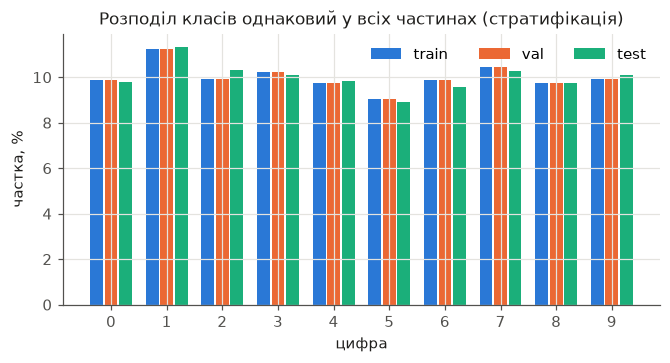

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.2))
w = 0.26
for i, col in enumerate(["train", "val", "test"]):
    ax.bar(np.arange(10) + (i - 1) * w, shares[col], width=w - 0.03, color=COLORS[i], label=col)
ax.set_xticks(range(10))
ax.set_xlabel("цифра")
ax.set_ylabel("частка, %")
ax.set_title("Розподіл класів однаковий у всіх частинах (стратифікація)")
ax.legend(ncol=3)
save_fig(fig, "01_class_distribution")
plt.show()

## 3. Приклади цифр

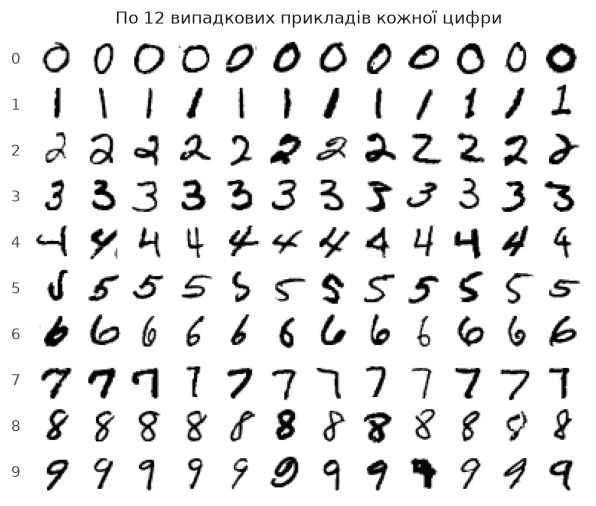

In [6]:
rng = np.random.default_rng(0)
examples = torch.cat([x_train[rng.choice(np.where(y_train.numpy() == c)[0], 12, replace=False)]
                      for c in range(10)])
fig, ax = plt.subplots(figsize=(6.5, 5.6))
show_grid(examples, nrow=10, ax=ax, title="По 12 випадкових прикладів кожної цифри",
          ylabels=[str(c) for c in range(10)])
save_fig(fig, "01_examples")
plt.show()

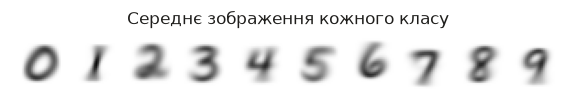

In [7]:
means = torch.stack([x_train[y_train == c].mean(0) for c in range(10)])
fig, ax = plt.subplots(figsize=(6.5, 1.2))
show_grid(means, nrow=1, ax=ax, title="Середнє зображення кожного класу")
save_fig(fig, "01_class_means")
plt.show()

## 4. Розподіл яскравості пікселів → вибір функції втрат

Якщо майже всі пікселі близькі до 0 або 1, природно моделювати кожен піксель як
**Бернуллі** і використовувати **бінарну крос-ентропію (BCE)** як втрату відновлення.

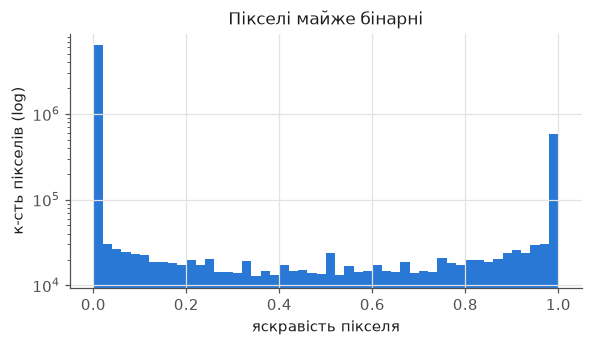

< 0.1: 82.5%   > 0.9: 8.8%   проміжні: 8.7%


In [8]:
px = x_train[:10000].flatten().numpy()
near0 = (px < 0.1).mean() * 100
near1 = (px > 0.9).mean() * 100
middle = 100 - near0 - near1

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(px, bins=50, color=COLORS[0])
ax.set_yscale("log")
ax.set_xlabel("яскравість пікселя")
ax.set_ylabel("к-сть пікселів (log)")
ax.set_title("Пікселі майже бінарні")
save_fig(fig, "01_pixel_hist")
plt.show()
print(f"< 0.1: {near0:.1f}%   > 0.9: {near1:.1f}%   проміжні: {middle:.1f}%")

## 5. Висновки

- MNIST: 60k train + 10k test, 28×28, відтінки сірого, значення нормовані до [0, 1].
- Фіксоване стратифіковане розбиття 55k / 5k / 10k (`data/split.json`, сід 42); класи збалансовані (~9–11% кожен).
- Пікселі майже бінарні → **Bernoulli-декодер + BCE**. Обмеження: проміжні значення (краї штрихів) теж
  обробляються BCE як «м'які» мітки; це стандартна практика для MNIST, але формально модель не є точною
  правдоподібністю для неперервних даних (див. розділ «Обмеження» у звіті).
- Препроцесинг мінімальний: лише ділення на 255. Без аугментацій — для генеративної моделі вони змінили б розподіл, який ми вчимося відтворювати.